# 02 - Full actor graph communities

This notebook runs weighted Leiden on the complete actor graph and evaluates community enrichment. Labels are used only after community fitting.

In [2]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.community import fit_leiden
from src.actor_features import load_actor_labels
from src.evaluation import cluster_enrichment
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

In [3]:
addresses = pd.Index(pd.read_csv(DATA / 'Actors_Dataset' / 'wallets_classes.csv', usecols=['address'])['address'].astype(str), name='address')
memberships, summary = fit_leiden(DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv', addresses, resolution=1.0)
labels = load_actor_labels(DATA / 'Actors_Dataset' / 'wallets_classes.csv').reindex(memberships.index)
enrichment = cluster_enrichment(memberships.to_numpy(), labels)
memberships.to_csv(RESULTS / 'leiden_memberships.csv', header=True)
enrichment.to_csv(RESULTS / 'leiden_enrichment.csv')
print(summary)
display(enrichment[enrichment['cluster_size'] >= 30].head(20))

{'input_edges_without_self_loops': 2822983, 'unique_undirected_edges': 2772474, 'communities': 887, 'modularity': 0.9212121253879861, 'largest_community': 72619}


,cluster_size,illicit_count,known_count,illicit_rate,global_illicit_rate,enrichment
cluster,,,,,,
40,1730,1142,1730,0.660116,0.053762,12.278446
48,1886,980,1886,0.519618,0.053762,9.665132
88,493,253,493,0.513185,0.053762,9.545463
57,1183,595,1183,0.502959,0.053762,9.355255
79,147,68,147,0.462585,0.053762,8.604289
74,1054,462,1054,0.438330,0.053762,8.153138
29,744,309,744,0.415323,0.053762,7.725186
97,664,265,664,0.399096,0.053762,7.423372
80,741,277,741,0.373819,0.053762,6.953204


In [ ]:
plot_data = enrichment.reset_index()
plot_data = plot_data[plot_data['cluster_size'] >= 30].head(30)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_data, x='cluster', y='enrichment', color='#c44e52', ax=ax)
ax.set_title('Top Leiden communities by illicit enrichment')
ax.set_xlabel('Community')
ax.set_ylabel('Enrichment over known-label baseline')
ax.tick_params(axis='x', rotation=70)
fig.tight_layout()
fig.savefig(FIGURES / 'leiden_enrichment_size30.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Size-controlled permutation test

The null model shuffles only known illicit/licit labels, preserving class counts and unknown-label positions. Community assignments remain fixed.

{'minimum_size': 30, 'permutations': 100, 'observed_max_enrichment': 12.27844642948309, 'null_mean_max_enrichment': 2.4355290302555535, 'null_95_max_enrichment': 3.100074769849058, 'empirical_p_value': 0.009900990099009901}
{'minimum_size': 100, 'permutations': 100, 'observed_max_enrichment': 12.27844642948309, 'null_mean_max_enrichment': 1.668729531530745, 'null_95_max_enrichment': 2.0240343243724648, 'empirical_p_value': 0.009900990099009901}
{'minimum_size': 500, 'permutations': 100, 'observed_max_enrichment': 12.27844642948309, 'null_mean_max_enrichment': 1.3448627101120447, 'null_95_max_enrichment': 1.52248242597327, 'empirical_p_value': 0.009900990099009901}


,minimum_size,permutations,observed_max_enrichment,null_mean_max_enrichment,null_95_max_enrichment,empirical_p_value
0,30,100,12.278446,2.435529,3.100075,0.009901
1,100,100,12.278446,1.668730,2.024034,0.009901
2,500,100,12.278446,1.344863,1.522482,0.009901


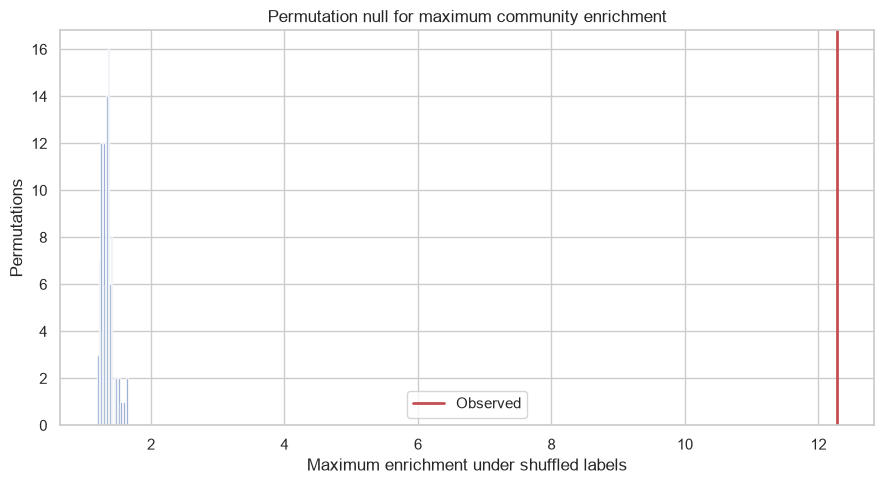

In [4]:
from src.robustness import permutation_enrichment_test

robustness_rows = []
for minimum_size in [30, 100, 500]:
    null_distribution, test_summary = permutation_enrichment_test(
        memberships.to_numpy(),
        labels.to_numpy(),
        minimum_size=minimum_size,
        permutations=100,
        random_state=42,
    )
    robustness_rows.append(test_summary)
    print(test_summary)
robustness = pd.DataFrame(robustness_rows)
robustness.to_csv(RESULTS / 'leiden_permutation_summary.csv', index=False)
display(robustness)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(null_distribution['null_max_enrichment'], bins=20, color='#4c72b0', alpha=0.8)
ax.axvline(test_summary['observed_max_enrichment'], color='#c44e52', linewidth=2, label='Observed')
ax.set_title('Permutation null for maximum community enrichment')
ax.set_xlabel('Maximum enrichment under shuffled labels')
ax.set_ylabel('Permutations')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'leiden_permutation_null.png', dpi=180, bbox_inches='tight')
plt.show()